In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [2]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)


ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418


In [12]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
#XCT = np.linspace(0, (NTOT)*AX, 35)
XCT = (NSC+NSM/2)*AX

# Define the boundary points
a = -100*AY
b = 0
c = M*AY
d = (M+100)*AY

# Define the number of points between each segment
n_ab = 50  # number of points between a and b
n_bc = 101  # number of points between b and c (more points)
n_cd = 50  # number of points between c and d

# Create linearly spaced points between each pair
y_ab = np.linspace(a, b, n_ab, endpoint=False)
y_bc = np.linspace(b, c, n_bc, endpoint=False)
y_cd = np.linspace(c, d, n_cd, endpoint=True)

# Concatenate all points
YCT = np.concatenate((y_ab, y_bc, y_cd))

print(YCT)


#YCT = np.linspace(-200*AY,(M+200)*AY,101)

print('X co-ordinate of charge trap =', XCT )

ZCT = 50
ZIM = 64
Ep = np.empty((YCT.shape[0],K_NUM))

for i in range(YCT.shape[0]):

    H = ModCT.H_sys(PHI, 'cu', XCT, YCT[i], ZCT, ZIM, f_ct=1)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep[i,:] = Es

    if i %10 ==0 :
        print(Ep[i,:])

np.save('cubic_E_vs_yct_Zdiff_{}_wider_yct_width_{}nm_refined.npy'.format(ZIM-ZCT ,LY), Ep)

[-500.         -490.         -480.         -470.         -460.
 -450.         -440.         -430.         -420.         -410.
 -400.         -390.         -380.         -370.         -360.
 -350.         -340.         -330.         -320.         -310.
 -300.         -290.         -280.         -270.         -260.
 -250.         -240.         -230.         -220.         -210.
 -200.         -190.         -180.         -170.         -160.
 -150.         -140.         -130.         -120.         -110.
 -100.          -90.          -80.          -70.          -60.
  -50.          -40.          -30.          -20.          -10.
    0.            2.97029703    5.94059406    8.91089109   11.88118812
   14.85148515   17.82178218   20.79207921   23.76237624   26.73267327
   29.7029703    32.67326733   35.64356436   38.61386139   41.58415842
   44.55445545   47.52475248   50.4950495    53.46534653   56.43564356
   59.40594059   62.37623762   65.34653465   68.31683168   71.28712871
   74.25742574 

In [32]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
#YCT = M/2*AY
#Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\cubic_E_vs_yct_Zdiff_0.20000000000000284.npy")

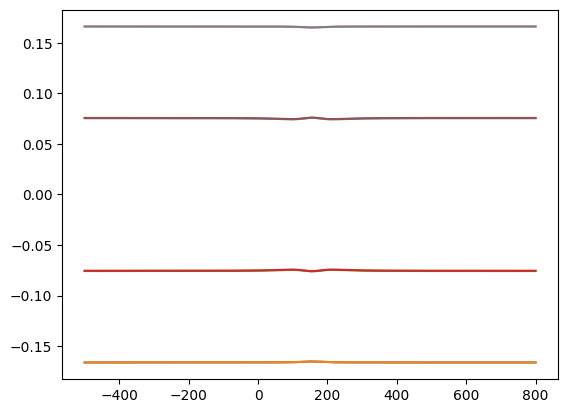

In [13]:
plt.plot(YCT, Ep[:, :])
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

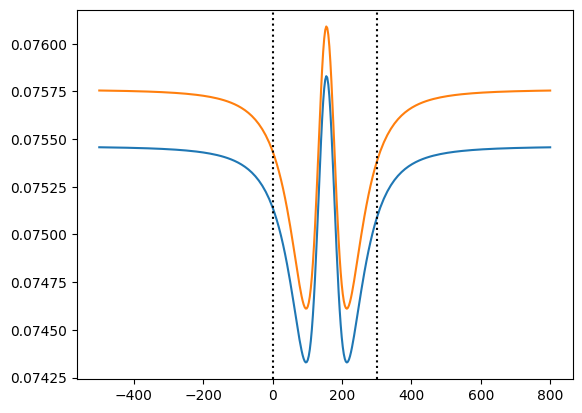

In [14]:
plt.plot(YCT, Ep[:, K_NUM//2:K_NUM//2+2])
plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

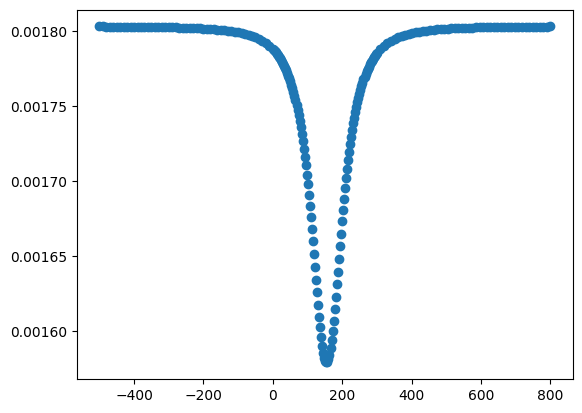

In [15]:
plt.scatter(YCT, (Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])/DELTA)
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

(0.0, 0.0018145450396938102)

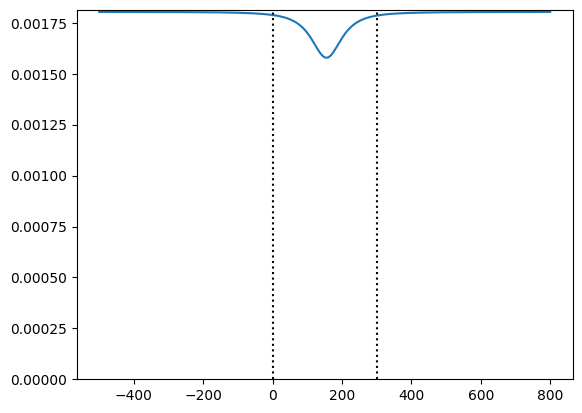

In [16]:
plt.plot(YCT, (Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])/DELTA)
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')
plt.ylim(ymin=0)

In [9]:
print(XCT)

4150.0


In [17]:
cubic_spin_split = Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)



In [24]:
print(max_spin_split/DELTA)

0.0018033189131519158


In [18]:
print(max_spin_split-min_spin_split)

3.7046217588251884e-05


In [19]:
percent_spin_split = (max_spin_split-min_spin_split)/max_spin_split

In [20]:
print(percent_spin_split)

0.12450517165899423


Text(0, 0.5, '$\\dfrac{E_s}{E_{s0}}$')

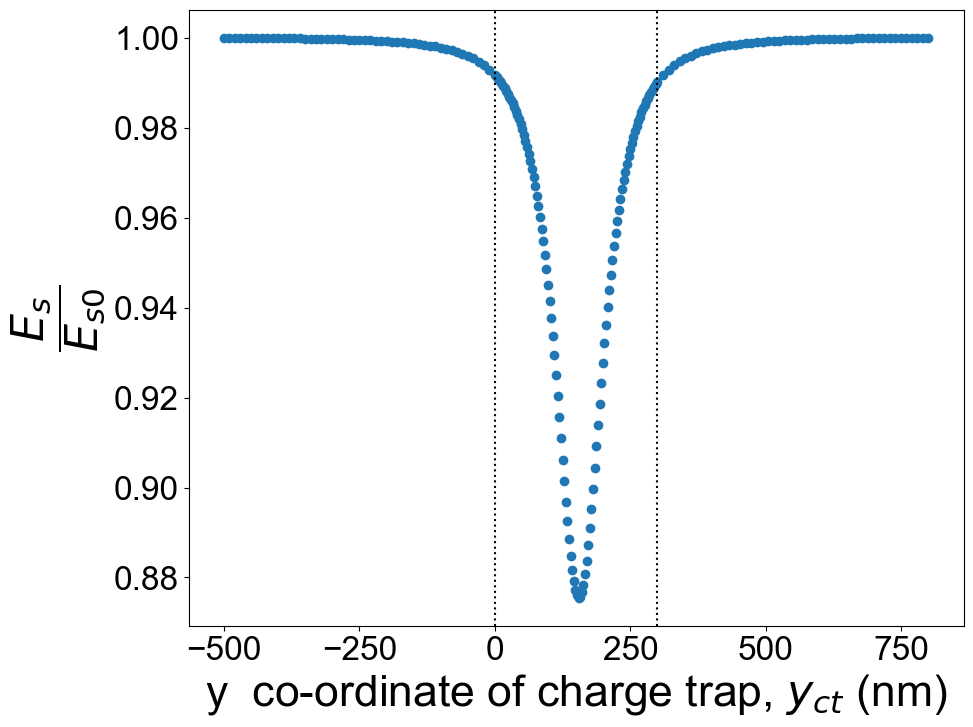

In [23]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

ax = plt.axis()

cubic_spin_split = Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)


Ep_wct = (Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])/max_spin_split

plt.scatter(YCT, Ep_wct )
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

plt.xlabel(r'y  co-ordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)

#plt.ylim(ymin=0)

(0.0, 0.00018943367049828463)

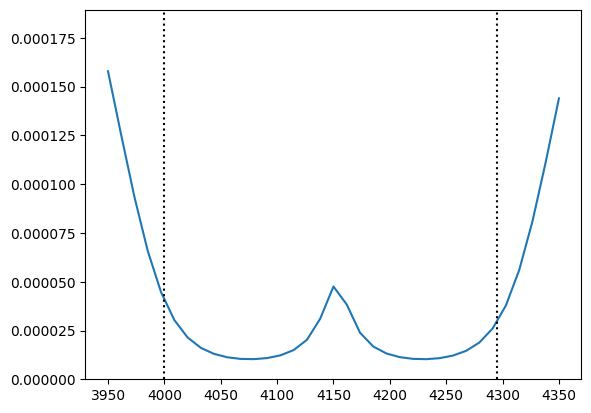

In [7]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

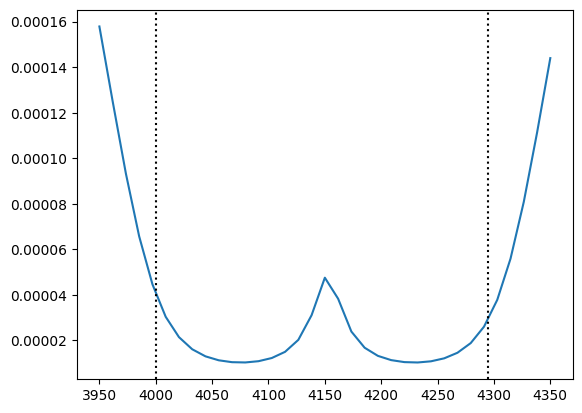

In [8]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

In [19]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\cubic_E_vs_xct_V1.npy")

(0.0, 0.00014110027318041672)

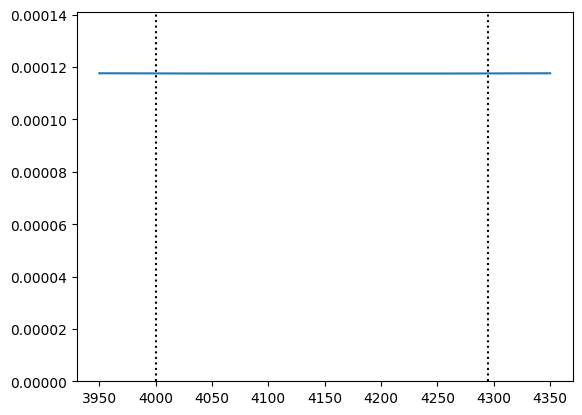

In [20]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

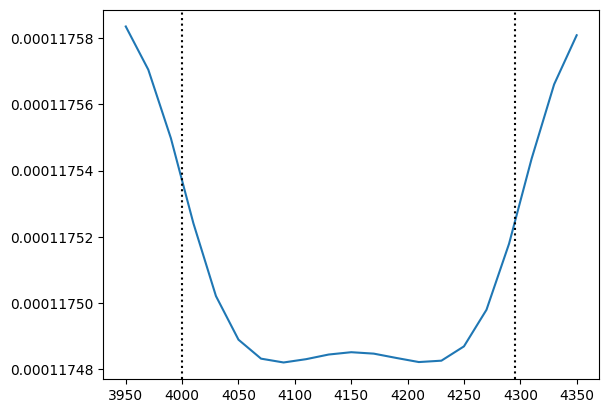

In [21]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))